# Recovery-only copy: completed full LPGNet factorial

The saved run log records **40/40 completed condition–fold tasks**. This copy is locked to recovery and reporting: `MAX_NEW_TASKS=0`, with a runner assertion that prevents any new training task.

1. Open this notebook in **Google Colab using the same Google account** that owns the original checkpoints.
2. Start a **fresh runtime**, then choose **Run all**. A GPU is not required for this recovery-only copy.
3. Keep the saved `RUN_PROFILE`, `RUN_ID`, `COHORT_POLICY`, and Drive settings unchanged. The Drive cell should restore the existing run, and the runner should report **40/40** and **Experiment complete: True**.
4. The summary, diagnostic, and plotting cells then reconstruct the results. Analysis CSV files are copied to `MyDrive/gait-checkpoints/factorial_efficient_v3/recovered_reports`.

Do not manually set `EXPERIMENT_COMPLETE=True`. If recovery reports an incomplete inventory, stop: no training will have started. Check that you are using the original Google account and Drive path.

*The saved outputs below are the original run log. New outputs produced during recovery will appear after you run the cells.*


# LPGNet — released-design reconstruction and selected leakage conditions

The default **efficient** profile runs `local__inner` only: ten outer folds, not a full factorial. `full` and `factorial_fast` retain all four explicitly labelled conditions: global/local control-reference LP fitting crossed with test-driven/training-only stopping. Test-driven or globally fitted conditions intentionally demonstrate leakage and are **not** clean test estimates.

## Read before running: profile and budget
- Choose the profile after the original configuration definitions. The scientific settings are frozen before training; changing profile, cohort or search requires a **new checkpoint RUN_ID and fresh kernel**, never relabelling an existing `run_result`.
- `efficient`: ten folds, one declared training seed, three-candidate setting (unused by this fixed-architecture factorial runner), epoch caps **100/40**, stopping/LR patience **12/5**, and frozen-encoder caching. Only `local__inner`: 20 training stages, at most 1,400 epochs.
- `full`: original **1,000/200** epoch caps, patience **25/14**, no frozen cache, all four conditions. The original budget is **4 × 10 × 2 = 80 stages**, up to **48,000 epochs**. A small model is not a small experiment.
- `factorial_fast`: all four conditions, caps 100/40, patience 12/5, frozen cache: 80 stages, up to 5,600 epochs. `fixed` sets one configuration; this runner already has a fixed architecture (no configuration CV).
- The accelerated path caches **inference-mode frozen encoders**, disabling frozen stochastic noise/dropout compared with the full original protocol. It does **not** preserve the original training distribution. Modern Keras regularizers also preclude a claim of bit-identical historical reproduction.

## Verified off-runtime recovery
Run the storage cell immediately before the runner **even with RUN_EXPERIMENT=False**. Colab support mounts Drive through its API; non-Colab use fails clearly until an authenticated **rclone off-runtime remote** is configured (required on Kaggle). Never paste credentials into cells. Temporary working folders are not durable storage.

A verified upload/download probe and automatic remote restore precede training. Every completed epoch commits model/optimizer, history and stopping/LR state to verified off-runtime storage; condition/fold tasks also commit. Re-running storage reuses the matching mirror and scratch directory. Local scratch may disappear safely after a verified commit; a crash mid-epoch can lose at most the current uncommitted epoch. Cloud failure stops training. Provider availability and permanent retention are not guaranteed. Use only one writer per RUN_ID.

`RUN_EXPERIMENT=False` initially; `MAX_NEW_TASKS=1` limits each invocation. Repeat the runner to continue. Manual ZIP export is optional portability, not recovery safety; leave `RESTORE_FROM_ZIP=''` because the durable runner restores automatically.

Default `COHORT_POLICY='official_all'` retains 306 official recordings including known cross-ID duplicates; even `local__inner` is not identity-clean under that policy. Choose `curated` with a new RUN_ID for the curated 161-participant cohort. Inputs and clinical metadata are checksum verified; local LP uses only early-stopping-core controls.

**Source pin:** SOURCE_REV is `52a050399d0330ad6dd76cf5499b7d1520e57f4d`. Strict checks include durable storage; do not bypass pin failures. No training or new results are supplied by this notebook update.

In [1]:
# Run this setup first in a fresh Kaggle/Colab kernel.
if 'run_result' in globals() or 'FROZEN_SCIENTIFIC_PROFILE' in globals():
    raise RuntimeError('Setup would reset a frozen run. Continue with the runner; use a fresh kernel and new RUN_ID for changes.')
import os, sys, tempfile, subprocess
from pathlib import Path
from collections import Counter
os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH','true')
SOURCE_REV = '52a050399d0330ad6dd76cf5499b7d1520e57f4d'  # Pinned committed support sources.
REPO_URL = 'https://github.com/AlexM3020/Subject-Independent-Evaluation-of-Mamba-for-Parkinson-s-Disease-Detection-from-Gait-Signals.git'
INSTALL_DEPENDENCIES = False
roots=[Path.cwd(),*Path.cwd().parents]
REPO_ROOT=next((p for b in roots for p in (b,b/'paper_repository') if (p/'gait/tf_notebook_support.py').is_file()),None)
if REPO_ROOT is None:
    REPO_ROOT=Path(tempfile.gettempdir())/('gait-keras-'+SOURCE_REV[:12])
    if not REPO_ROOT.exists(): subprocess.run(['git','clone','--no-checkout',REPO_URL,str(REPO_ROOT)],check=True)
    subprocess.run(['git','-C',str(REPO_ROOT),'checkout','--detach',SOURCE_REV],check=True)
REPO_ROOT=REPO_ROOT.resolve()
for filename in ('__init__.py','official_data.py','tf_notebook_support.py','durable_storage.py'):
    expected=subprocess.run(['git','-C',str(REPO_ROOT),'show',SOURCE_REV+':gait/'+filename],capture_output=True,check=True).stdout
    assert (REPO_ROOT/'gait'/filename).read_bytes().replace(b'\r\n',b'\n')==expected.replace(b'\r\n',b'\n'), 'Pinned source changed: '+filename
stale=[name for name,module in list(sys.modules.items()) if (name=='gait' or name.startswith('gait.')) and getattr(module,'__file__',None) and not Path(module.__file__).resolve().is_relative_to(REPO_ROOT)]
if stale: raise RuntimeError('Older gait imports cached: restart kernel and run this setup first. '+str(stale))
sys.path.insert(0,str(REPO_ROOT))
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable,'-m','pip','install','-r',str(REPO_ROOT/'requirements-tensorflow.txt')],check=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
keras=tf.keras
from scipy.signal import lfilter
from sklearn.metrics import (roc_auc_score,accuracy_score,balanced_accuracy_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,log_loss,roc_curve)
from IPython.display import display
from gait import tf_notebook_support as nb
FAMILY='factorial'
SEED,FOLD_SEED,SPLIT_SEED,SEARCH_SEED=1,0,9137,20261117
N_FOLDS,N_INNER,VAL_FRAC=10,3,.15
LP_ORDER,WIN,STRIDE=11,100,50
BATCH_WIN,BATCH_REC=128,64
LR_WIN,LR_REC,LABEL_SMOOTH,L2_REG=5e-4,1e-3,.1,1e-3
MAX_EPOCHS_WIN,MAX_EPOCHS_REC=1000,200
PATIENCE,RLR_PATIENCE,MIN_LR=25,14,1e-7
N_BOOT=1000
THRESHOLD=.5
WORK_ROOT=Path('/kaggle/working') if Path('/kaggle').exists() else Path('/content') if Path('/content').exists() else Path.cwd()
# CHECKPOINT_DIR and OUTDIR are assigned by the verified storage cell, not to an ephemeral run directory here.
CACHE_DIR=Path(tempfile.gettempdir())/'gaitpdb-1.0.0-verified-cache'
COHORT_POLICY='official_all'  # Keeps original duplicates for reconstruction; not an identity-clean cohort.
ALLOW_DOWNLOAD=True
RUN_EXPERIMENT=True
MAX_NEW_TASKS=0  # Recovery only: never start a missing task.
VERBOSE_EPOCHS=1
RESTORE_FROM_ZIP=''  # Legacy only: do not use with automatic durable restore.
EXPERIMENT_COMPLETE=False
summary=participant_ci=participant_fold_metrics=oof=fold_metrics=pd.DataFrame()
participants=participant_errors=pd_severity=by_study=seed_stability=pd.DataFrame()
keras.utils.set_random_seed(SEED)
print('Pinned source:',SOURCE_REV,'| TensorFlow:',tf.__version__,'| Keras:',keras.__version__)
print('GPU:',tf.config.list_physical_devices('GPU'))
print('Select the scientific profile, then verify off-runtime storage before enabling training.')
print('Four-condition profiles include deliberate leakage; efficient runs local__inner only, not a full factorial.')

Pinned source: 52a050399d0330ad6dd76cf5499b7d1520e57f4d | TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Select the scientific profile, then verify off-runtime storage before enabling training.
Four-condition profiles include deliberate leakage; efficient runs local__inner only, not a full factorial.


In [2]:
import time
from urllib.error import HTTPError, URLError

MAX_ATTEMPTS = 6
RETRYABLE_HTTP_CODES = {429, 500, 502, 503, 504}

for attempt in range(1, MAX_ATTEMPTS + 1):
    try:
        records, clinical, data_audit, data_provenance = nb.load_inputs(
            CACHE_DIR,
            COHORT_POLICY,
            ALLOW_DOWNLOAD
        )
        print(f'Input loading succeeded on attempt {attempt}.')
        break

    except (HTTPError, URLError, TimeoutError) as exc:
        retryable = (
            not isinstance(exc, HTTPError)
            or exc.code in RETRYABLE_HTTP_CODES
        )

        if not retryable or attempt == MAX_ATTEMPTS:
            raise

        wait_seconds = min(120, 5 * 2 ** (attempt - 1))
        print(
            f'Download attempt {attempt}/{MAX_ATTEMPTS} failed: {exc}. '
            f'Retrying in {wait_seconds} seconds...'
        )
        time.sleep(wait_seconds)

subjects = sorted({r['subject'] for r in records})
subj_label = {r['subject']: r['label'] for r in records}
by_file = {r['file']: i for i, r in enumerate(records)}
by_subject = {
    s: [i for i, r in enumerate(records) if r['subject'] == s]
    for s in subjects
}

print('Cohort policy:', COHORT_POLICY)
print(
    len(records),
    'recordings |',
    len(subjects),
    'participants |',
    dict(Counter(subj_label.values()))
)
print('Data provenance:', data_provenance)
print(
    'Clinical unknowns are retained; '
    'no severity is inferred from filenames.'
)

Input loading succeeded on attempt 1.
Cohort policy: official_all
306 recordings | 165 participants | {0: 72, 1: 93}
Data provenance: {'cohort': {'policy': 'official_all', 'manifest_sha256': '44903ce52d5428ba218a9cdfd60d5646ab6674df4926233c756ae7c3c7cd50ec', 'warning': 'Original-all retains known cross-ID duplicates, including conflicting labels. Not a clean cohort.'}, 'clinical': {'source': 'https://physionet.org/files/gaitpdb/1.0.0/', 'manifest_sha256': '44903ce52d5428ba218a9cdfd60d5646ab6674df4926233c756ae7c3c7cd50ec', 'files': {'demographics.txt': 'ebe5e3c5c3055023b876225d3eb067a9351693e28ce47fa678872ead8284f643', 'demographics.html': '26871fae0ea56ace5260ed9c31eaeaf1f5d374df53a03ba8493d8308deaf6658'}, 'issues': [{'raw_id': 'Juc010', 'reason': 'invalid_exact_id_or_short_row'}], 'join': 'exact study-qualified ID; TXT/HTML HY and identity cross-check'}}
Clinical unknowns are retained; no severity is inferred from filenames.


In [3]:
def preprocess(x):
    return lfilter([.5,.5],1,x,axis=0)[::2]

def fit_lp(control_sigs,order=LP_ORDER):
    return nb.fit_lp(control_sigs,order)

def apply_lp(x,C,stds):
    return nb.apply_lp(x,C,stds)

def lp_features(indices,C,stds):
    return {i:apply_lp(records[i]['proc'],C,stds) for i in indices}

for r in records:
    r['proc']=preprocess(r['signal'])
print('Fixed label-free downsampling prepared. LP fitting is deferred to the declared experimental condition.')

Fixed label-free downsampling prepared. LP fitting is deferred to the declared experimental condition.


In [4]:
def make_folds():
    return nb.outer_folds(records,N_FOLDS,FOLD_SEED)

def split_val(indices,frac=VAL_FRAC,seed=SEED):
    return nb.subject_split(records,indices,frac,seed)

def labels(indices):
    return np.array([records[i]['label'] for i in indices],np.float32)

FOLDS=make_folds()
for k,f in enumerate(FOLDS):
    print('Fold',k,'train participants:',len({records[i]['subject'] for i in f['train']}),
          'test participants:',len({records[i]['subject'] for i in f['test']}))

Fold 0 train participants: 148 test participants: 17
Fold 1 train participants: 148 test participants: 17
Fold 2 train participants: 148 test participants: 17
Fold 3 train participants: 148 test participants: 17
Fold 4 train participants: 148 test participants: 17
Fold 5 train participants: 149 test participants: 16
Fold 6 train participants: 149 test participants: 16
Fold 7 train participants: 149 test participants: 16
Fold 8 train participants: 149 test participants: 16
Fold 9 train participants: 149 test participants: 16


In [5]:
# Supported Keras API; models and training are version-pinned in the shared helper.
def build_lpgnet(**kwargs):
    return nb.build_lpgnet(**kwargs)

def build_recording_model(window_model):
    return nb.build_recording_model(window_model)

MODEL_READY=False
smoke=nb.smoke_check(FAMILY,{})
print('Real forward/backward and model/optimizer reload:',smoke)
MODEL_READY=True
print('Training uses bounded-memory batches and automatic atomic epoch checkpoints after RUN_EXPERIMENT=True.')
print('No obsolete workers/use_multiprocessing arguments are passed to Keras fit.')

Real forward/backward and model/optimizer reload: {'family': 'factorial', 'parameters': 4735, 'tensorflow': '2.21.0', 'keras': '3.13.2', 'safe_model_optimizer_roundtrip': True, 'padding_invariance': False}
Training uses bounded-memory batches and automatic atomic epoch checkpoints after RUN_EXPERIMENT=True.
No obsolete workers/use_multiprocessing arguments are passed to Keras fit.


In [6]:
# ============================================================
# OOF metrics, participant aggregation, errors, and clinical subgroups
# ============================================================
def _validated_binary_inputs(y, p):
    y = np.asarray(y)
    p = np.asarray(p)
    if y.ndim != 1 or p.ndim != 1 or len(y) == 0 or len(y) != len(p):
        raise ValueError('Labels and probabilities must be nonempty 1-D arrays of equal length.')
    if np.iscomplexobj(y) or not np.isin(y, [0, 1]).all():
        raise ValueError('Labels must contain only binary values 0 and 1.')
    if np.iscomplexobj(p):
        raise ValueError('Probabilities must be real numbers in [0, 1].')
    p = np.asarray(p, float)
    if not np.isfinite(p).all() or ((p < 0) | (p > 1)).any():
        raise ValueError('Probabilities must be finite and in [0, 1].')
    return y.astype(int), p

def metric_dict(y, p):
    y, p = _validated_binary_inputs(y, p)
    yh = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0,1]).ravel()
    return dict(n=len(y), accuracy=accuracy_score(y, yh),
                balanced_accuracy=balanced_accuracy_score(y, yh),
                macro_f1=f1_score(y, yh, labels=[0,1], average='macro', zero_division=0),
                f1_pd=f1_score(y, yh, zero_division=0),
                sensitivity=tp/(tp+fn) if tp+fn else np.nan,
                specificity=tn/(tn+fp) if tn+fp else np.nan,
                roc_auc=roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
                log_loss=log_loss(y, np.clip(p,1e-7,1-1e-7), labels=[0,1]),
                brier=float(np.mean((p-y)**2)))

def oof_frame(rows):
    df = pd.DataFrame(rows)
    y, p = _validated_binary_inputs(df['label'], df['probability'])
    df['label'] = y; df['probability'] = p
    df['prediction'] = (df['probability'] >= 0.5).astype(int)
    df['correct'] = (df['prediction'] == df['label']).astype(int)
    df['confidence'] = np.maximum(df['probability'], 1-df['probability'])
    df['nll'] = -(df['label']*np.log(np.clip(df['probability'],1e-7,1)) +
                  (1-df['label'])*np.log(np.clip(1-df['probability'],1e-7,1)))
    # Strict metadata lookup: missing subjects or fields raise KeyError.
    for col in ('study','diagnosis','hy','hy_label','hy_status','age','gender'):
        df[col] = df['subject'].map(lambda s: clinical[s][col])
    return df

def participant_oof(df, group_cols):
    """Equal weight per participant; probability is averaged over that person's walks."""
    keys = group_cols + ['subject']
    df = df.copy()
    y, p = _validated_binary_inputs(df['label'], df['probability'])
    df['label'] = y; df['probability'] = p
    if df[keys + ['fold']].isna().any().any():
        raise ValueError('Participant grouping keys and folds must not be missing.')
    grouped = df.groupby(keys, as_index=False)
    counts = grouped[['label', 'fold']].nunique(dropna=False)
    if (counts['label'] > 1).any():
        raise ValueError('Conflicting labels for a subject within an evaluation group.')
    if (counts['fold'] > 1).any():
        raise ValueError('Multiple folds for a subject within an evaluation group.')
    if 'file' in df.columns and df.duplicated(subset=group_cols + ['file']).any():
        raise ValueError('Duplicate file within an evaluation group.')
    agg = dict(label=('label','first'), fold=('fold','first'), probability=('probability','mean'),
               recordings=('file','nunique') if 'file' in df.columns else ('subject','size'))
    out = grouped.agg(**agg)
    return oof_frame(out.to_dict('records'))

def summarize_oof(df, group_cols):
    rows = []
    for keys, g in df.groupby(group_cols):
        if not isinstance(keys, tuple): keys = (keys,)
        base = dict(zip(group_cols, keys))
        rec = metric_dict(g['label'], g['probability'])
        part = participant_oof(g, group_cols)
        pm = metric_dict(part['label'], part['probability'])
        rows.append({**base, **{'recording_'+k:v for k,v in rec.items()}})
        rows[-1].update({'participant_'+k:v for k,v in pm.items()})
    return pd.DataFrame(rows)

def wilson_interval(correct, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    ph = correct/n; den = 1+z*z/n
    center = (ph+z*z/(2*n))/den
    half = z*np.sqrt(ph*(1-ph)/n+z*z/(4*n*n))/den
    return center-half, center+half

def error_tables(df, group_cols):
    part = participant_oof(df, group_cols)
    errors = part[part['correct'] == 0].sort_values(group_cols+['nll'], ascending=[True]*len(group_cols)+[False])
    pd_rows = []
    for keys, g in part[part['label'] == 1].groupby(group_cols+['hy_label'], dropna=False):
        if not isinstance(keys, tuple): keys = (keys,)
        base = dict(zip(group_cols+['hy_label'], keys))
        n = len(g); correct = int(g['correct'].sum()); lo, hi = wilson_interval(correct, n)
        pd_rows.append({**base, 'pd_participants':n, 'correct':correct, 'errors':n-correct,
                        'pd_sensitivity':correct/n, 'wilson_95_low':lo, 'wilson_95_high':hi})
    study_rows = []
    for keys, g in part.groupby(group_cols+['study','diagnosis']):
        if not isinstance(keys, tuple): keys = (keys,)
        base = dict(zip(group_cols+['study','diagnosis'], keys))
        study_rows.append({**base, **metric_dict(g['label'], g['probability'])})
    return part, errors, pd.DataFrame(pd_rows), pd.DataFrame(study_rows)

def show_table(df, title, limit=100):
    print('\n'+title)
    display(df.head(limit))

def pooled_bootstrap(df, group_cols, metrics=('accuracy','balanced_accuracy','macro_f1','sensitivity','specificity','roc_auc')):
    """Stratified participant bootstrap conditional on fitted OOF predictions."""
    rows = []
    for keys, g in df.groupby(group_cols):
        if not isinstance(keys, tuple): keys = (keys,)
        base = dict(zip(group_cols, keys))
        part = participant_oof(g, group_cols).reset_index(drop=True)
        y = part['label'].to_numpy(); p = part['probability'].to_numpy()
        class_idx = [np.flatnonzero(y == c) for c in (0,1)]
        rng = np.random.default_rng(2026)
        for metric in metrics:
            observed = metric_dict(y,p)[metric]
            vals = []
            for _ in range(N_BOOT):
                ii = np.concatenate([rng.choice(ix, len(ix), replace=True) for ix in class_idx])
                vals.append(metric_dict(y[ii],p[ii])[metric])
            rows.append({**base,'metric':metric,'estimate':observed,
                         'bootstrap_95_low':np.nanpercentile(vals,2.5),
                         'bootstrap_95_high':np.nanpercentile(vals,97.5)})
    return pd.DataFrame(rows)

def plot_confusion_and_roc(df, group_cols, title_col):
    part = participant_oof(df, group_cols)
    groups = list(part.groupby(group_cols))
    fig, axes = plt.subplots(len(groups), 2, figsize=(11,4.3*len(groups)), squeeze=False)
    for row, (keys,g) in enumerate(groups):
        if not isinstance(keys, tuple): keys=(keys,)
        title = ' | '.join(f'{c}={v}' for c,v in zip(group_cols,keys))
        cm = confusion_matrix(g['label'],g['prediction'],labels=[0,1])
        ConfusionMatrixDisplay(cm,display_labels=['Control','PD']).plot(ax=axes[row,0],colorbar=False)
        axes[row,0].set_title(title+' | participant OOF')
        fpr,tpr,_ = roc_curve(g['label'],g['probability'])
        axes[row,1].plot(fpr,tpr,label=f"AUC={roc_auc_score(g['label'],g['probability']):.3f}")
        axes[row,1].plot([0,1],[0,1],'--',color='gray')
        axes[row,1].set(xlabel='False-positive rate',ylabel='True-positive rate',title=title)
        axes[row,1].legend()
    fig.tight_layout(); plt.show()


In [7]:
# Declare the scientific budget AFTER original configuration definitions, BEFORE storage/training.
RUN_PROFILE='full'  # Options: efficient, full, factorial_fast, fixed. Changes need a new RUN_ID.
REQUIRE_GPU=False  # Recovery only; new training is disabled by MAX_NEW_TASKS=0.
_PROFILE_KEYS=('SOURCE_REV','FAMILY','SEED','FOLD_SEED','SPLIT_SEED','SEARCH_SEED','N_FOLDS','N_INNER',
    'VAL_FRAC','LP_ORDER','WIN','STRIDE','BATCH_WIN','BATCH_REC','PRED_BATCH','LR_WIN','LR_REC',
    'LABEL_SMOOTH','L2_REG','MAX_EPOCHS_WIN','MAX_EPOCHS_REC','MAX_EPOCHS_MIL','PATIENCE',
    'RLR_PATIENCE','MIN_LR','TRAIN_SEEDS','N_TRIALS','THRESHOLD','COHORT_POLICY','SPACE_A',
    'SPACE_RESMIL','EXPORT_ATTENTION','RUN_PROFILE','CACHE_FROZEN_ENCODER','CONDITIONS')
def scientific_profile(namespace):
    return nb.json_ready({k:namespace[k] for k in _PROFILE_KEYS if k in namespace})
_proposed=scientific_profile({**globals(),**nb.profile_settings(FAMILY,RUN_PROFILE)})
if 'run_result' in globals() and 'FROZEN_SCIENTIFIC_PROFILE' not in globals():
    raise RuntimeError('Existing run_result has no frozen profile. Use a fresh kernel and new checkpoint RUN_ID; do not relabel results.')
if 'FROZEN_SCIENTIFIC_PROFILE' in globals() and _proposed!=globals()['FROZEN_SCIENTIFIC_PROFILE']:
    raise RuntimeError('Scientific profile changed. Start a fresh kernel with a new checkpoint RUN_ID.')
globals().update(nb.profile_settings(FAMILY,RUN_PROFILE))
CONDITIONS=globals()['CONDITIONS']  # Explicit binding for notebook static analysis after namespace update.
FROZEN_SCIENTIFIC_PROFILE=scientific_profile(globals())
print('Frozen profile:',RUN_PROFILE,'| conditions:',CONDITIONS)
print('Budget:',nb.budget_report(globals(),FAMILY))
print('Original four-condition budget: 4 x 10 x 2 = 80 training stages; 48,000 maximum epochs. Small model != small experiment.')
print('Efficient is local__inner only, NOT a full factorial; full and factorial_fast retain all four conditions.')
print('Cached frozen encoders run in inference mode: frozen noise/dropout is disabled, unlike the full original protocol; training distributions are not identical.')

Frozen profile: full | conditions: [['global', 'test'], ['local', 'test'], ['global', 'inner'], ['local', 'inner']]
Budget: {'outer_tasks': 40, 'two_stage_fits': 40, 'training_stages': 80, 'maximum_total_epochs': 48000}
Original four-condition budget: 4 x 10 x 2 = 80 training stages; 48,000 maximum epochs. Small model != small experiment.
Efficient is local__inner only, NOT a full factorial; full and factorial_fast retain all four conditions.
Cached frozen encoders run in inference mode: frozen noise/dropout is disabled, unlike the full original protocol; training distributions are not identical.


In [8]:
# REQUIRED preflight, even when RUN_EXPERIMENT=False. This cell never starts training.
RUN_ID='factorial_efficient_v3'  # Original completed run; do not change for recovery.
STORAGE_BACKEND='colab_drive'
DRIVE_ROOT='/content/drive/MyDrive/gait-checkpoints'
RCLONE_REMOTE=''  # Kaggle: choose 'rclone' and a real authenticated remote, e.g. researchdrive:gait-checkpoints.
# Configure rclone authentication outside notebook cells; never paste credentials or tokens here.
REQUIRE_DURABLE_STORAGE=True
if RESTORE_FROM_ZIP:
    raise RuntimeError('Leave RESTORE_FROM_ZIP empty. Durable storage restores automatically; do not mix manual ZIP state.')
_storage_settings=(STORAGE_BACKEND,DRIVE_ROOT,RCLONE_REMOTE)
if globals().get('DURABLE_RUN_ID')!=RUN_ID or globals().get('DURABLE_MIRROR') is None:
    if 'run_result' in globals():
        raise RuntimeError('Existing run_result cannot be rebound to another mirror. Restart the kernel; use the same RUN_ID to resume or a new ID for a new plan.')
    CHECKPOINT_DIR=Path(tempfile.mkdtemp(prefix='gait-scratch-'))
    DURABLE_MIRROR=nb.connect_storage(CHECKPOINT_DIR,RUN_ID,backend=STORAGE_BACKEND,
        drive_root=DRIVE_ROOT,rclone_remote=RCLONE_REMOTE)
    DURABLE_RUN_ID=RUN_ID
    DURABLE_STORAGE_SETTINGS=_storage_settings
else:
    DURABLE_MIRROR=globals()['DURABLE_MIRROR']
    CHECKPOINT_DIR=Path(globals()['CHECKPOINT_DIR'])
    if globals().get('DURABLE_STORAGE_SETTINGS')!=_storage_settings:
        raise RuntimeError('Storage settings changed for this RUN_ID. Restart and reconnect explicitly; do not mix backends.')
    if DURABLE_MIRROR.local_root!=CHECKPOINT_DIR.resolve():
        raise RuntimeError('Mirror does not match CHECKPOINT_DIR. Restart and restore into fresh scratch.')
    DURABLE_MIRROR.verified=False  # A failed re-probe must not leave a stale success flag.
    DURABLE_MIRROR.verify()  # Repeat upload/download probe, without overwriting local progress.
if not DURABLE_MIRROR.verified:
    raise RuntimeError('Storage verification failed; training is disabled.')
OUTDIR=CHECKPOINT_DIR/'reports'
print('Verified durable run:',DURABLE_RUN_ID,'| local scratch:',CHECKPOINT_DIR)
print('Automatic restore complete. Epoch commits are verified off-runtime; cloud failures stop training. No training started.')

Mounted at /content/drive
Restored 121 verified checkpoint units from durable storage.
Verified durable run: factorial_efficient_v3 | local scratch: /tmp/gait-scratch-5ebo15ue
Automatic restore complete. Epoch commits are verified off-runtime; cloud failures stop training. No training started.


In [9]:
# Execute only the selected conditions; local__inner excludes validation controls from LP fitting.
if RUN_EXPERIMENT:
    assert MAX_NEW_TASKS==0, 'Recovery copy is locked: no new training tasks are permitted.'
    assert MODEL_READY,'Run the real model checkpoint smoke test first'
    if scientific_profile(globals())!=FROZEN_SCIENTIFIC_PROFILE:
        raise RuntimeError('Frozen scientific profile changed; use a fresh kernel and new RUN_ID.')
    if RESTORE_FROM_ZIP:
        raise RuntimeError('Do not use manual ZIP restore; the storage cell restores committed state automatically.')
    assert REQUIRE_DURABLE_STORAGE,'Keep verified durable storage enabled'
    assert DURABLE_RUN_ID==RUN_ID and DURABLE_STORAGE_SETTINGS==(STORAGE_BACKEND,DRIVE_ROOT,RCLONE_REMOTE),'Rerun storage preflight'
    assert DURABLE_MIRROR.verified and DURABLE_MIRROR.local_root==Path(CHECKPOINT_DIR).resolve(),'Verify the matching storage mirror first'
    experiment=nb.NotebookExperiment(globals(),FAMILY)  # Engine consumes DURABLE_MIRROR and verifies requirements.
    run_result=experiment.factorial(max_tasks=MAX_NEW_TASKS)
    globals().update(nb.unpack_result(globals(),run_result,FAMILY))
    print('Complete condition/fold tasks:',len(run_result['fold_rows']),'/',len(CONDITIONS)*N_FOLDS)
    print('Experiment complete:',EXPERIMENT_COMPLETE)
    if not EXPERIMENT_COMPLETE:
        raise RuntimeError('The original run did not recover a complete inventory. No training was started; verify the Google account, Drive path, RUN_ID, and profile.')
else:
    EXPERIMENT_COMPLETE=False
    print('Training disabled. Verify storage even now; set RUN_EXPERIMENT=True only after profile and preflight checks.')

DURABLE: run-plan revision 2 verified (0.0s)
DURABLE: task/f25c5396a1022718488a7f6d5044940af1482465b31aa0d9bf70154ded502fe1 revision 2 verified (0.0s)
DURABLE: task/c62cfc9cee6e1967c3cbf3e391938b233156c75a4e91e45ed1886d99c48bacb8 revision 2 verified (0.0s)
DURABLE: task/3deca9b71f02952fec7218f27f41be9eb4d49c53689cfb71586a7f8e90fe1a6b revision 2 verified (0.0s)
DURABLE: task/ad8290353e314fa5b7936388ea067bb9093def3252622511c32a64908e4f8598 revision 2 verified (0.0s)
DURABLE: task/69431e278a8b9c8b64d14efa16c945eefc3b66b2c78d5cf5bb75eeb2e804c45e revision 2 verified (0.0s)
DURABLE: task/5461d88305378ec9061e8d27d426fc8775004470b6a44f6eafeef587a6c406e1 revision 2 verified (0.0s)
DURABLE: task/082cbbac6bf025cba865d73d866005c596b1b69e8ca8e9974d87040c9058f14e revision 2 verified (0.0s)
DURABLE: task/ac672879d69e61b43904f0f54350f6020e75cc24b9a24a445029adaf802762a2 revision 2 verified (0.0s)
DURABLE: task/53820568f0cd9ff0908e1e814b19d5ce4eb83b999481dd213c9bc0c4626f114b revision 2 verified (0.0s)
D

In [10]:
print('Recovered tasks:', len(run_result['fold_rows']), '/', len(CONDITIONS)*N_FOLDS)
print('Recovered OOF rows:', len(oof))
print(oof.groupby('condition')['file'].nunique())

if EXPERIMENT_COMPLETE:
    globals().update(nb.summary_tables(globals(),FAMILY))
    show_table(summary.round(4),'Complete pooled recording and participant OOF metrics for selected conditions')
    show_table(participant_ci.round(4),'Participant-stratified bootstrap intervals, conditional on fitted predictions')
    show_table(participant_fold_metrics.round(4),'Participant fold metrics; fold SD is not a confidence interval')
    if 'global__test' in set(fold_metrics['condition']):
        paper=pd.DataFrame({'paper_reported_mean':[.917,.903,.932],'paper_reported_sd':[.094,.058,.036]},index=['roc_auc','accuracy','f1_pd'])
        current=fold_metrics[fold_metrics.condition=='global__test'][['roc_auc','accuracy','f1_pd']].agg(['mean','std']).T
        paper['reconstructed_mean']=current['mean']; paper['reconstructed_sd']=current['std']
        show_table(paper.round(4),'Published versus modernized global/test condition; report profile and cache protocol, not exact reproduction')
    else:
        print('No published global/test comparison: global__test was not run in this profile.')
else:
    print('Complete every selected condition/fold before interpreting results; efficient is not a full factorial.')

Recovered tasks: 40 / 40
Recovered OOF rows: 1224
condition
global__inner    306
global__test     306
local__inner     306
local__test      306
Name: file, dtype: int64

Complete pooled recording and participant OOF metrics for selected conditions


,condition,recording_n,recording_accuracy,recording_balanced_accuracy,recording_macro_f1,recording_f1_pd,recording_sensitivity,recording_specificity,recording_roc_auc,recording_log_loss,...,participant_n,participant_accuracy,participant_balanced_accuracy,participant_macro_f1,participant_f1_pd,participant_sensitivity,participant_specificity,participant_roc_auc,participant_log_loss,participant_brier
0,global__inner,306,0.7941,0.7196,0.7345,0.8603,0.9065,0.5326,0.8293,0.4562,...,165,0.7273,0.7047,0.7064,0.7847,0.8817,0.5278,0.8154,0.5340,0.1772
1,global__test,306,0.9020,0.8617,0.8778,0.9321,0.9626,0.7609,0.9311,0.3139,...,165,0.8606,0.8497,0.8552,0.8832,0.9355,0.7639,0.9147,0.3803,0.1188
2,local__inner,306,0.7647,0.6738,0.6876,0.8428,0.9019,0.4457,0.8471,0.4442,...,165,0.7091,0.6823,0.6810,0.7757,0.8925,0.4722,0.8359,0.5285,0.1757
3,local__test,306,0.8824,0.8322,0.8512,0.9193,0.9579,0.7065,0.9307,0.3172,...,165,0.8424,0.8289,0.8350,0.8700,0.9355,0.7222,0.9120,0.3845,0.1206



Participant-stratified bootstrap intervals, conditional on fitted predictions


,condition,metric,estimate,bootstrap_95_low,bootstrap_95_high
0,global__inner,accuracy,0.7273,0.6606,0.7939
1,global__inner,balanced_accuracy,0.7047,0.6362,0.7679
2,global__inner,macro_f1,0.7064,0.6333,0.7757
3,global__inner,sensitivity,0.8817,0.8065,0.9462
4,global__inner,specificity,0.5278,0.4163,0.6389
5,global__inner,roc_auc,0.8154,0.7466,0.8778
6,global__test,accuracy,0.8606,0.8061,0.9091
7,global__test,balanced_accuracy,0.8497,0.7919,0.9021
8,global__test,macro_f1,0.8552,0.7999,0.9060
9,global__test,sensitivity,0.9355,0.8817,0.9785



Participant fold metrics; fold SD is not a confidence interval


,condition,fold,n,accuracy,balanced_accuracy,macro_f1,f1_pd,sensitivity,specificity,roc_auc,log_loss,brier
0,global__inner,0,17,0.6471,0.6319,0.6136,0.7273,0.8889,0.3750,0.8889,0.4750,0.1561
1,global__inner,1,17,0.7647,0.7500,0.7424,0.8182,1.0000,0.5000,0.8333,0.5977,0.1789
2,global__inner,2,17,0.7059,0.6857,0.6886,0.7619,0.8000,0.5714,0.7714,0.5992,0.2029
3,global__inner,3,17,0.8235,0.8500,0.8235,0.8235,0.7000,1.0000,0.9286,0.3939,0.1266
4,global__inner,4,17,0.7647,0.7571,0.7571,0.8000,0.8000,0.7143,0.8571,0.4562,0.1488
5,global__inner,5,16,0.8125,0.7857,0.7922,0.8571,1.0000,0.5714,0.8730,0.4277,0.1443
6,global__inner,6,16,0.5625,0.5000,0.3600,0.7200,1.0000,0.0000,0.9206,0.6901,0.2484
7,global__inner,7,16,0.5625,0.5317,0.5152,0.6667,0.7778,0.2857,0.7937,0.7619,0.2567
8,global__inner,8,16,0.6875,0.6429,0.6135,0.7826,1.0000,0.2857,0.8095,0.6315,0.2200
9,global__inner,9,16,0.9375,0.9444,0.9373,0.9412,0.8889,1.0000,0.9365,0.3159,0.0933



Published versus modernized global/test condition; report profile and cache protocol, not exact reproduction


,paper_reported_mean,paper_reported_sd,reconstructed_mean,reconstructed_sd
roc_auc,0.917,0.094,0.9083,0.1061
accuracy,0.903,0.058,0.9044,0.0425
f1_pd,0.932,0.036,0.9337,0.0265


In [11]:
if EXPERIMENT_COMPLETE:
    globals().update(nb.error_reports(globals(),FAMILY))
    paired_comparisons=nb.paired_tables(globals(),FAMILY)  # Engine uses only conditions actually selected.
    if paired_comparisons.empty:
        print('Only one selected condition: no paired condition contrast is available.')
    else:
        show_table(paired_comparisons.round(4),'Paired selected-condition differences, first minus second')
        print('Positive accuracy/AUC favors the first condition; negative log loss/Brier favors the first.')
        print('Leakage contrasts are not independent clinical-validation claims.')
else:
    print('Paired comparisons require completion of every selected condition/fold.')

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics


Paired selected-condition differences, first minus second


,comparison,metric,difference,bootstrap_95_low,bootstrap_95_high,participants,paired_seeds
0,global__test minus local__test,accuracy,0.0182,-0.0121,0.0545,165,1
1,global__test minus local__test,balanced_accuracy,0.0208,-0.0092,0.0562,165,1
2,global__test minus local__test,macro_f1,0.0202,-0.0113,0.0571,165,1
3,global__test minus local__test,sensitivity,0.0000,-0.0430,0.0430,165,1
4,global__test minus local__test,specificity,0.0417,0.0000,0.0972,165,1
5,global__test minus local__test,roc_auc,0.0027,-0.0094,0.0152,165,1
6,global__test minus local__test,log_loss,-0.0042,-0.0217,0.0137,165,1
7,global__test minus local__test,brier,-0.0018,-0.0084,0.0050,165,1
8,global__inner minus local__inner,accuracy,0.0182,-0.0182,0.0545,165,1
9,global__inner minus local__inner,balanced_accuracy,0.0224,-0.0177,0.0625,165,1


Positive accuracy/AUC favors the first condition; negative log loss/Brier favors the first.
Leakage contrasts are not independent clinical-validation claims.


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/usr/local/lib/python3.13/dist-packages/sklearn/metrics

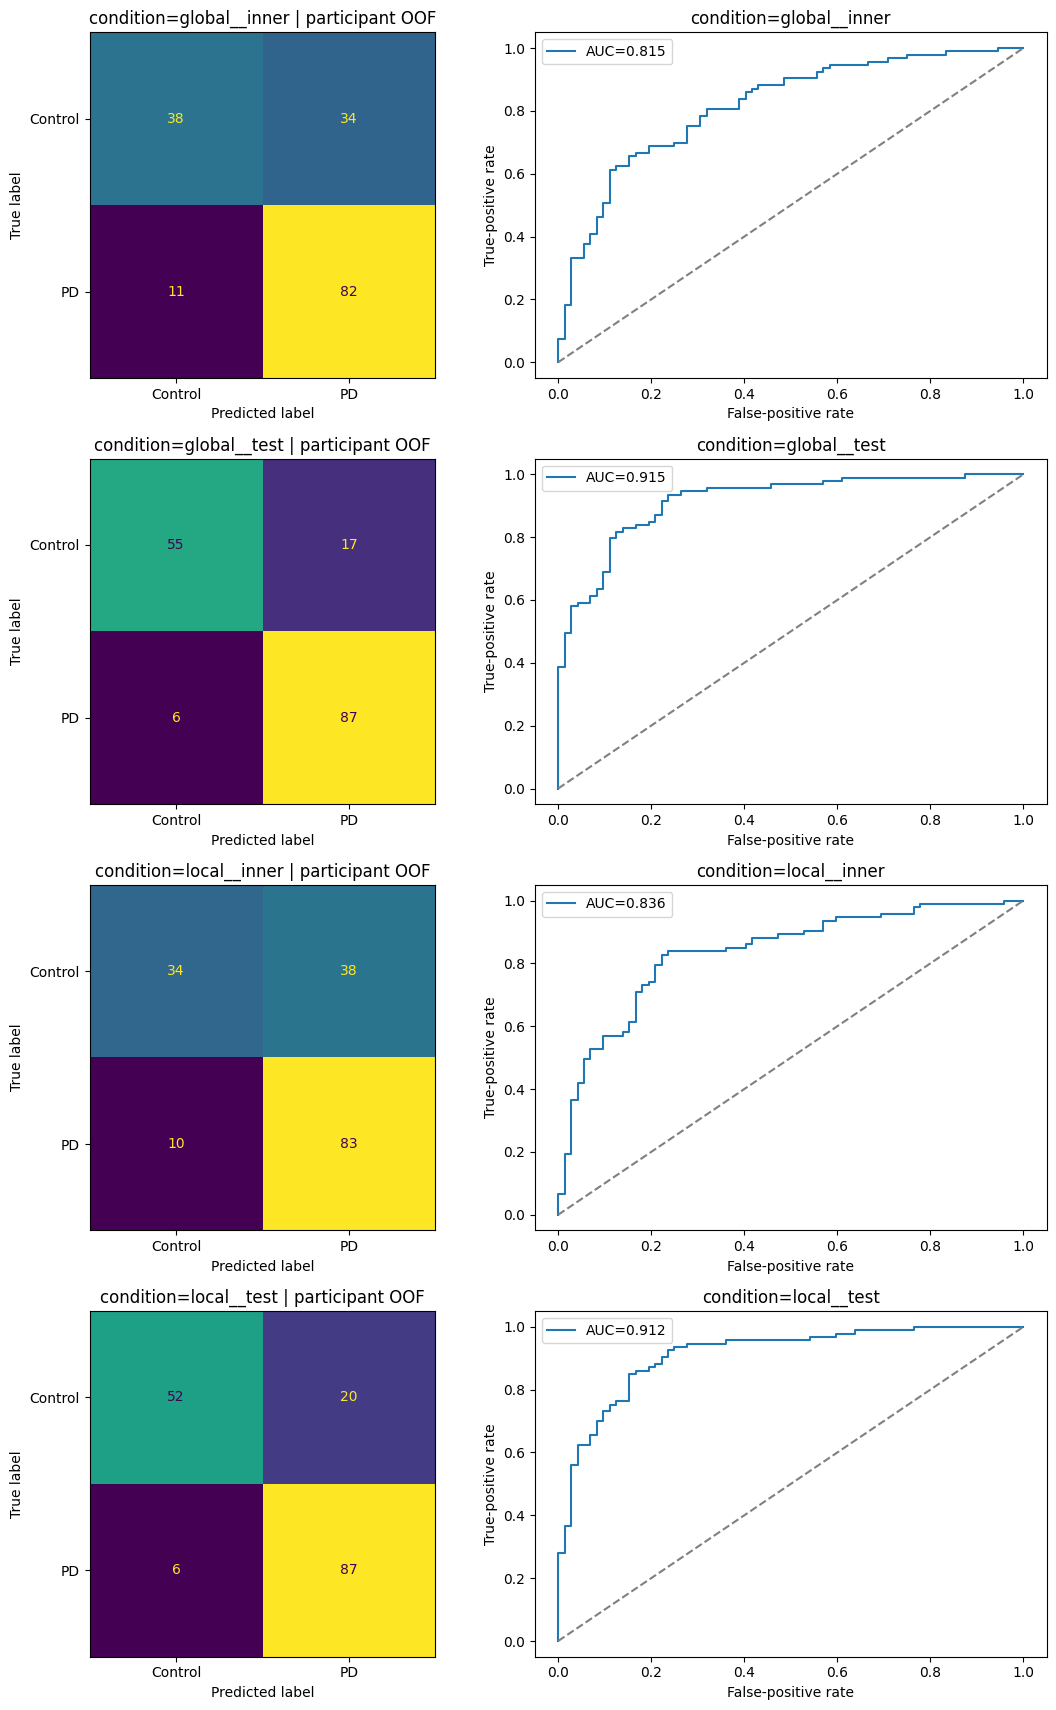


All participant OOF errors and successes


,condition,subject,label,fold,probability,recordings,prediction,correct,confidence,nll,study,diagnosis,hy,hy_label,hy_status,age,gender
472,local__inner,SiPt17,1,7,0.0232,1,0,0,0.9768,3.7655,Si,PD,2.0,2.0,verified,64.0,1
57,global__inner,JuCo12,0,1,0.9705,1,1,0,0.9705,3.5229,Ju,Control,NaN,Not applicable,not_applicable,72.0,2
142,global__inner,SiPt17,1,7,0.0335,1,0,0,0.9665,3.3968,Si,PD,2.0,2.0,verified,64.0,1
387,local__inner,JuCo12,0,1,0.9651,1,1,0,0.9651,3.3563,Ju,Control,NaN,Not applicable,not_applicable,72.0,2
307,global__test,SiPt17,1,7,0.0543,1,0,0,0.9457,2.9135,Si,PD,2.0,2.0,verified,64.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
262,global__test,JuPt26,1,2,0.6150,6,1,1,0.6150,0.4861,Ju,PD,2.0,2.0,verified,66.0,2
620,local__test,SiCo26,0,9,0.3837,1,0,1,0.6163,0.4841,Si,Control,NaN,Not applicable,not_applicable,60.0,1
67,global__inner,JuCo22,0,7,0.3787,1,0,1,0.6213,0.4759,Ju,Control,NaN,Not applicable,not_applicable,62.0,2
600,local__test,SiCo06,0,1,0.3777,1,0,1,0.6223,0.4744,Si,Control,NaN,Not applicable,not_applicable,70.0,2



Misclassified participants


,condition,subject,label,fold,probability,recordings,prediction,correct,confidence,nll,study,diagnosis,hy,hy_label,hy_status,age,gender
57,global__inner,JuCo12,0,1,0.9705,1,1,0,0.9705,3.5229,Ju,Control,NaN,Not applicable,not_applicable,72.0,2
142,global__inner,SiPt17,1,7,0.0335,1,0,0,0.9665,3.3968,Si,PD,2.0,2.0,verified,64.0,1
65,global__inner,JuCo20,0,2,0.9325,1,1,0,0.9325,2.6952,Ju,Control,NaN,Not applicable,not_applicable,67.0,2
71,global__inner,JuCo26,0,1,0.9034,1,1,0,0.9034,2.3371,Ju,Control,NaN,Not applicable,not_applicable,60.0,1
127,global__inner,SiCo28,0,8,0.8922,1,1,0,0.8922,2.2274,Si,Control,NaN,Not applicable,not_applicable,61.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,local__test,JuCo24,0,2,0.5509,1,1,0,0.5509,0.8005,Ju,Control,NaN,Not applicable,not_applicable,64.0,1
610,local__test,SiCo16,0,0,0.5375,1,1,0,0.5375,0.7710,Si,Control,NaN,Not applicable,not_applicable,60.0,1
621,local__test,SiCo27,0,9,0.5122,1,1,0,0.5122,0.7178,Si,Control,NaN,Not applicable,not_applicable,67.0,1
510,local__test,GaCo16,0,7,0.5109,3,1,0,0.5109,0.7151,Ga,Control,NaN,Not applicable,not_applicable,63.0,2



PD sensitivity by verified HY stage (unknown retained)


,condition,hy_label,pd_participants,correct,errors,pd_sensitivity,wilson_95_low,wilson_95_high
0,global__inner,2.0,55,44,11,0.8000,0.6763,0.8845
1,global__inner,2.5,28,28,0,1.0000,0.8794,1.0000
2,global__inner,3.0,10,10,0,1.0000,0.7225,1.0000
3,global__test,2.0,55,49,6,0.8909,0.7817,0.9490
4,global__test,2.5,28,28,0,1.0000,0.8794,1.0000
5,global__test,3.0,10,10,0,1.0000,0.7225,1.0000
6,local__inner,2.0,55,45,10,0.8182,0.6967,0.8981
7,local__inner,2.5,28,28,0,1.0000,0.8794,1.0000
8,local__inner,3.0,10,10,0,1.0000,0.7225,1.0000
9,local__test,2.0,55,49,6,0.8909,0.7817,0.9490



Study-by-diagnosis metrics


,condition,study,diagnosis,n,accuracy,balanced_accuracy,macro_f1,f1_pd,sensitivity,specificity,roc_auc,log_loss,brier
0,global__inner,Ga,Control,18,0.5556,0.5556,0.3571,0.0000,NaN,0.5556,NaN,0.7221,0.2599
1,global__inner,Ga,PD,29,0.9310,0.9310,0.4821,0.9643,0.9310,NaN,NaN,0.2372,0.0603
2,global__inner,Ju,Control,25,0.4400,0.4400,0.3056,0.0000,NaN,0.4400,NaN,0.9446,0.3259
3,global__inner,Ju,PD,29,0.9310,0.9310,0.4821,0.9643,0.9310,NaN,NaN,0.2718,0.0789
4,global__inner,Si,Control,29,0.5862,0.5862,0.3696,0.0000,NaN,0.5862,NaN,0.6423,0.2306
5,global__inner,Si,PD,35,0.8000,0.8000,0.4444,0.8889,0.8000,NaN,NaN,0.5173,0.1623
6,global__test,Ga,Control,18,0.7778,0.7778,0.4375,0.0000,NaN,0.7778,NaN,0.5734,0.1978
7,global__test,Ga,PD,29,1.0000,1.0000,0.5000,1.0000,1.0000,NaN,NaN,0.1374,0.0244
8,global__test,Ju,Control,25,0.7600,0.7600,0.4318,0.0000,NaN,0.7600,NaN,0.5619,0.1892
9,global__test,Ju,PD,29,1.0000,1.0000,0.5000,1.0000,1.0000,NaN,NaN,0.2041,0.0459



Errors recurring across factorial conditions (not training seeds)


,subject,error_conditions,mean_nll
0,GaCo01,1,0.8860
1,GaCo03,2,0.9831
2,GaCo04,4,1.3442
3,GaCo05,4,1.1415
4,GaCo06,4,1.8164
5,GaCo07,2,0.7716
6,GaCo08,4,1.3743
7,GaCo12,1,0.7543
8,GaCo14,1,0.8761
9,GaCo15,2,1.8656


In [12]:
if EXPERIMENT_COMPLETE:
    globals().update(nb.error_reports(globals(),FAMILY))
    plot_confusion_and_roc(oof,['condition'],'condition')
    show_table(participants.sort_values('nll',ascending=False).round(4),'All participant OOF errors and successes',limit=200)
    show_table(participant_errors.round(4),'Misclassified participants',limit=200)
    show_table(pd_severity.round(4),'PD sensitivity by verified HY stage (unknown retained)')
    show_table(by_study.round(4),'Study-by-diagnosis metrics')
    show_table(seed_stability.round(4),'Errors recurring across factorial conditions (not training seeds)')
else:
    print('Complete all conditions before reviewing outer errors.')

In [13]:
# Recovery reporting: no checkpoint ZIP is needed because the verified Drive run already exists.
EXPORT_CHECKPOINT_BUNDLE=False
EXPORT_ANALYSIS_CSV=True
if EXPORT_CHECKPOINT_BUNDLE:
    print('Optional checkpoint ZIP:',nb.export_checkpoint_bundle(CHECKPOINT_DIR))
    print('Download this optional copy if wanted; do not mix manual ZIP restore with the durable runner.')
if EXPORT_ANALYSIS_CSV:
    if not EXPERIMENT_COMPLETE: raise RuntimeError('Analysis export requires complete OOF results')
    nb.export_tables(globals(),FAMILY)
    if STORAGE_BACKEND=='colab_drive':
        import shutil
        recovered_reports=Path(DRIVE_ROOT)/RUN_ID/'recovered_reports'
        shutil.copytree(Path(CHECKPOINT_DIR)/'reports',recovered_reports,dirs_exist_ok=True)
        print('Recovered analysis tables saved in Google Drive:',recovered_reports)


Analysis tables: /tmp/gait-scratch-5ebo15ue/reports
Recovered analysis tables saved in Google Drive: /content/drive/MyDrive/gait-checkpoints/factorial_efficient_v3/recovered_reports


## Reporting and persistence limits

- Report frozen profile, selected condition labels, all folds and cohort policy with every result. `efficient` is local/inner only, not a full factorial. `global` LP uses held-out controls; `test` validation uses held-out outcomes for stopping. These are deliberate leakage conditions, not deployable evaluation pipelines.
- `official_all` retains cross-ID duplicates: even local/inner is not certified identity-clean under this policy.
- Keras 3 regularizers, bounded-memory batches and inference-mode frozen caching are explicit protocol choices. Topology/two-stage structure alone do not imply historical numerical reproduction or identical stochastic training distributions.
- Pair only available conditions by participant on identical folds. One condition provides no pairwise contrast. Published global/test comparisons are shown only when that condition is present. Bootstrap intervals condition on fitted predictions; fold SD is not repeated-training uncertainty.
- Checkpoints bind data/source/configuration. Do not edit CSVs to mark completion, merge runs, change profiles in place or reuse another cohort's RUN_ID.
- Per-epoch verified off-runtime commits make local scratch disposable after commit. Automatic restore replaces manual ZIP recovery. A mid-epoch crash can lose the current epoch; storage failure stops training. Cloud-provider availability and permanent retention are not guaranteed.
- Smoke checks validate actual models and serialization on the chosen runtime. This update does not supply new full-cohort training results.